# Immuno Compass · Notebook 09: Sequence-derived features, go / no-go (Days 11–12)

**Question:** the label-style clues (origin, modality, backbone…) leave most drug-to-drug variation unexplained.
Can features computed from each drug's **amino-acid sequence** capture some of it?

**Finish line:** sequence features built and linked; a **pre-registered** test on unseen drugs for three models; a clear
**keep / reject** decision reported honestly either way.

> 🧒 *Simple version:* every protein drug is a long word written with 20 letters (amino acids). We measure simple
> properties of that word (how long, how charged, how water-hating) and check whether they help predict ADA.

### Decision rule (fixed before looking at results)
Keep the sequence features **only if**, on grouped CV (unseen drugs), adding them **improves the average score and is
better in at least 4 of the 5 folds** for the model in question. Otherwise: *"tested, no improvement"*.

### The features (whole molecule: chains × copies joined, e.g. 2 heavy + 2 light for an IgG)
| Feature | Meaning | Why it could matter |
|---|---|---|
| `seq_log_length` | size (log of amino-acid count) | bigger molecules offer more possible "foreign-looking" pieces |
| `seq_pI` | isoelectric point (charge balance) | charge affects uptake by immune cells |
| `seq_gravy` | average hydrophobicity | hydrophobic patches promote clumping (aggregates are immunogenic) |
| `seq_aromaticity` | share of F/W/Y | linked to aggregation and binding |
| `seq_instability` | in-vitro instability index | unstable proteins may degrade or aggregate |

Only 5 features on purpose: with ~100 drugs, many sequence features (e.g. all 20 amino-acid fractions) would let models
memorise drugs.

In [ ]:
# ---- Setup: works both in Colab and on a laptop ----
import sys, os
from pathlib import Path

if "google.colab" in sys.modules and not Path("/content/immuno-compass").exists():
    # The repo is private, so Colab needs a GitHub token once per session.
    # Make one at github.com/settings/tokens (fine-grained, read access to immuno-compass).
    from getpass import getpass
    token = getpass("GitHub token: ")
    !git clone -q https://{token}@github.com/shibilshamz/immuno-compass.git /content/immuno-compass
    del token
if "google.colab" in sys.modules:
    os.chdir("/content/immuno-compass")
    !pip install -q statsmodels xgboost pymc arviz biopython

# Make the shared helper module (src/immuno.py) importable from any folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "immuno.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import immuno as im
print("repo root:", ROOT.name)

repo root: immuno-compass


In [ ]:
import warnings, logging
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import spearmanr
from sklearn.model_selection import GroupKFold
np.random.seed(42)
for msg in ["Found unknown categories", ".*BLAS.*"]:
    warnings.filterwarnings("ignore", message=msg)
warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("pymc").setLevel(logging.ERROR)

BLUE, ORANGE, AQUA, GRAY, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "savefig.dpi": 200, "savefig.bbox": "tight", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID})

## 1 · Build the features and check coverage

In [ ]:
seqf = im.load_sequence_features(ROOT)
df = (im.load_cohorts(ROOT).join(im.load_folds(ROOT)[["fold_grouped"]])
        .merge(seqf, on=im.DRUG, how="left"))
df["has_sequence"] = df["seq_pI"].notna()
print(f"drugs with a sequence: {len(seqf)} in the therapeutics table, {df.loc[df.has_sequence, im.DRUG].nunique()} of {df[im.DRUG].nunique()} drugs in our cohorts")
print(f"cohorts with sequence features: {df['has_sequence'].mean():.1%}  → above the 50 % rule, so the main test uses ALL cohorts")
print("(missing → median + 'missing' flag, fit inside each training fold)\n")
display(pd.crosstab(df.drop_duplicates(im.DRUG)["species"], df.drop_duplicates(im.DRUG)["has_sequence"], margins=True)
          .rename(columns={True: "has sequence", False: "no sequence"}))
display(seqf[im.SEQ_FEATURES].describe().round(2))

drugs with a sequence: 176 in the therapeutics table, 104 of 137 drugs in our cohorts
cohorts with sequence features: 89.3%  → above the 50 % rule, so the main test uses ALL cohorts
(missing → median + 'missing' flag, fit inside each training fold)


has_sequence,no sequence,has sequence,All
species,,,
Bacterial,6,0,6
Chimeric,1,15,16
Human,12,35,47
Humanized,14,53,67
Other,0,1,1
All,33,104,137


,seq_log_length,seq_pI,seq_gravy,seq_aromaticity,seq_instability
count,176.00,176.00,176.00,176.00,176.00
mean,6.87,7.99,-0.37,0.09,46.13
std,0.70,0.86,0.10,0.01,5.71
min,3.61,4.56,-0.54,0.06,10.66
25%,6.84,7.59,-0.42,0.09,45.35
50%,7.19,8.35,-0.40,0.10,46.92
75%,7.19,8.55,-0.37,0.10,48.42
max,7.65,9.21,0.18,0.14,56.40


⚠️ **None of the 6 bacterial drugs have a sequence**, and bacterial drugs have very high ADA, so "sequence missing" partly
stands in for "bacterial". The `species` feature already carries that, so the missing-flag adds little new.

## 2 · A first look: drug-level ADA vs each sequence feature
One dot per drug (pooled ADA over its cohorts), dot size ∝ patients. Spearman ρ measures any monotone trend.

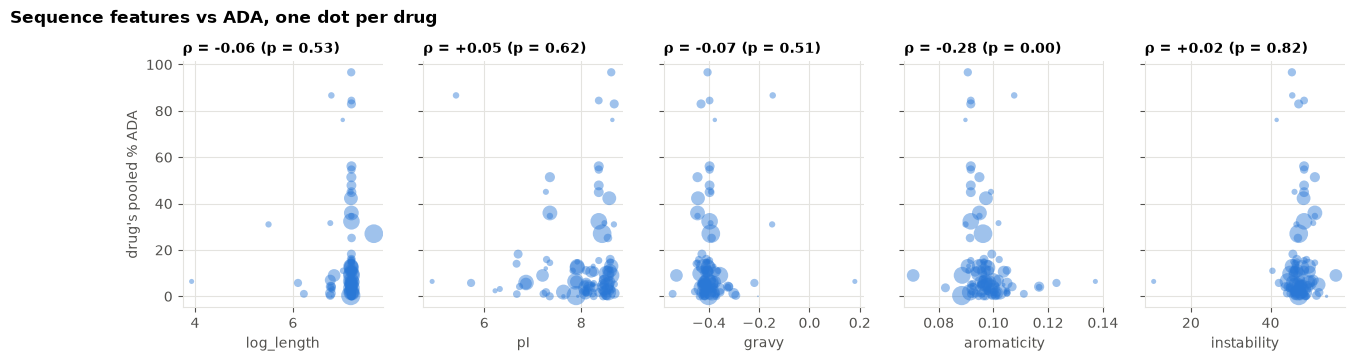

In [ ]:
drug = (df[df.has_sequence].groupby(im.DRUG)
          .agg(y=("y", "sum"), n=("n", "sum"), **{f: (f, "first") for f in im.SEQ_FEATURES}, species=("species", "first")))
drug["ada"] = drug["y"] / drug["n"]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2), sharey=True)
for ax, f in zip(axes, im.SEQ_FEATURES):
    r, p = spearmanr(drug[f], drug["ada"])
    ax.scatter(drug[f], drug["ada"] * 100, s=np.sqrt(drug["n"]) * 1.5, color=BLUE, alpha=0.45, lw=0)
    ax.set_xlabel(f.replace("seq_", "")); ax.set_title(f"ρ = {r:+.2f} (p = {p:.2f})", fontsize=10)
axes[0].set_ylabel("drug's pooled % ADA")
fig.suptitle("Sequence features vs ADA, one dot per drug", x=0.01, ha="left", fontweight="bold", y=1.04)
fig.savefig(ROOT / "figures" / "seq_features_vs_ada.png"); plt.show()

## 3 · The real test: does adding them help on unseen drugs?

Same 5 grouped folds, same scores. Each model is run **without** and **with** the 5 sequence features
(+ a missing flag), everything else identical:
1. **GLM + L2** (penalty tuned by nested CV, as on Day 5)
2. **XGBoost** (plan settings, as on Day 6)
3. **Bayesian Beta-Binomial** (as on Day 10; ~3 min)

In [ ]:
ALPHAS = [0.1, 0.3, 1, 3, 10, 30]
def glm_l2_tuned(extra):
    def fn(train, test):
        best_a, best_ll = None, -np.inf
        for a in ALPHAS:
            lls = []
            for tr_i, va_i in GroupKFold(n_splits=4).split(train, groups=train[im.GROUP]):
                tr, va = train.iloc[tr_i], train.iloc[va_i]
                pre, params = im.fit_glm(tr, alpha=a, L1_wt=0.0, extra_num=extra)
                lls.append(im.mean_loglik(va["y"], va["n"], im.predict_glm(pre, params, va)))
            if np.mean(lls) > best_ll: best_a, best_ll = a, np.mean(lls)
        pre, params = im.fit_glm(train, alpha=best_a, L1_wt=0.0, extra_num=extra)
        return im.predict_glm(pre, params, test)
    return fn

def xgb_plan(extra):
    def fn(train, test):
        pre, model = im.fit_xgb(train, max_depth=4, weight="n", extra_num=extra)
        return im.predict_xgb(pre, model, test)
    return fn

lps_store = {}
def bayes_bb(extra, key):
    lps_store[key] = []
    def fn(train, test):
        pre, samples, idata = im.fit_bayes(train, kind="betabinomial", extra_num=extra)
        pr = im.bayes_predictive(pre, samples, test)
        inside = (test["y"].values >= pr["lo"]) & (test["y"].values <= pr["hi"])
        lps_store[key].append({"lps": pr["lps"].mean(), "coverage": inside.mean()})
        return im.predict_bayes(pre, samples, test)
    return fn

runs = {}
for label, maker in [("GLM + L2", glm_l2_tuned), ("XGBoost", xgb_plan)]:
    for with_seq in [False, True]:
        extra = im.SEQ_FEATURES if with_seq else []
        pf, oof = im.cross_validate(df, "fold_grouped", maker(extra))
        runs[(label, with_seq)] = pf
        print(f"{label:9s} {'with' if with_seq else 'without'} sequence:", {k: round(v, 4) for k, v in pf.drop(columns='fold').mean().items()})
    im.save_results({"GLM + L2": "glm_l2_seq", "XGBoost": "xgb_default_seq"}[label], runs[(label, True)], oof, df, ROOT)

GLM + L2  without sequence: {'wMAE': 0.1321, 'wRMSE': 0.1825, 'loglik': -18.6711}


GLM + L2  with sequence: {'wMAE': 0.1291, 'wRMSE': 0.182, 'loglik': -19.1655}


XGBoost   without sequence: {'wMAE': 0.128, 'wRMSE': 0.1804, 'loglik': -19.7708}


XGBoost   with sequence: {'wMAE': 0.1152, 'wRMSE': 0.1767, 'loglik': -19.9183}


In [ ]:
for with_seq in [False, True]:
    extra = im.SEQ_FEATURES if with_seq else []
    key = f"bb_{with_seq}"
    pf, oof = im.cross_validate(df, "fold_grouped", bayes_bb(extra, key))
    pf = pf.join(pd.DataFrame(lps_store[key]))
    runs[("Beta-Binomial", with_seq)] = pf
    print(f"Beta-Binomial {'with' if with_seq else 'without'} sequence:",
          {k: round(v, 4) for k, v in pf.drop(columns='fold').mean().items()})
im.save_results("bayes_betabinomial_seq", runs[("Beta-Binomial", True)].drop(columns=["lps", "coverage"]), oof, df, ROOT)

Beta-Binomial without sequence: {'wMAE': 0.1587, 'wRMSE': 0.2088, 'loglik': -21.6357, 'lps': -2.969, 'coverage': 0.8757}


Beta-Binomial with sequence: {'wMAE': 0.156, 'wRMSE': 0.2077, 'loglik': -21.7719, 'lps': -3.0111, 'coverage': 0.8535}


## 4 · Paired comparison per fold and the decision

For each model and fold: score **with** minus score **without**. Negative is better for errors; positive is better for log-likelihood / lps.

In [ ]:
rows = []
for label in ["GLM + L2", "XGBoost", "Beta-Binomial"]:
    a, b = runs[(label, False)].set_index("fold"), runs[(label, True)].set_index("fold")
    metrics = [("wMAE", "lower"), ("wRMSE", "lower"), ("loglik", "higher")] + ([("lps", "higher")] if label == "Beta-Binomial" else [])
    for m, better in metrics:
        d = b[m] - a[m]
        wins = int((d < 0).sum() if better == "lower" else (d > 0).sum())
        improves = (d.mean() < 0) if better == "lower" else (d.mean() > 0)
        rows.append({"model": label, "metric": m, "without": a[m].mean(), "with sequence": b[m].mean(),
                     "difference": d.mean(), "fold SD of diff": d.std(), "folds improved": f"{wins}/5",
                     "passes rule": bool(improves and wins >= 4)})
decision = pd.DataFrame(rows)
display(decision.style.format({"without": "{:.4f}", "with sequence": "{:.4f}", "difference": "{:+.4f}", "fold SD of diff": "{:.4f}"})
        .apply(lambda r: ["background-color:#e6f4ea" if r["passes rule"] else "" for _ in r], axis=1).hide(axis="index"))

model,metric,without,with sequence,difference,fold SD of diff,folds improved,passes rule
GLM + L2,wMAE,0.1321,0.1291,-0.0030,0.0048,3/5,False
GLM + L2,wRMSE,0.1825,0.1820,-0.0005,0.0011,3/5,False
GLM + L2,loglik,-18.6711,-19.1655,-0.4944,1.1797,3/5,False
XGBoost,wMAE,0.1280,0.1152,-0.0128,0.0186,3/5,False
XGBoost,wRMSE,0.1804,0.1767,-0.0037,0.0132,3/5,False
XGBoost,loglik,-19.7708,-19.9183,-0.1475,3.7100,3/5,False
Beta-Binomial,wMAE,0.1587,0.1560,-0.0027,0.0066,4/5,True
Beta-Binomial,wRMSE,0.2088,0.2077,-0.0011,0.0087,3/5,False
Beta-Binomial,loglik,-21.6357,-21.7719,-0.1362,1.0269,2/5,False
Beta-Binomial,lps,-2.9690,-3.0111,-0.0421,0.0586,2/5,False


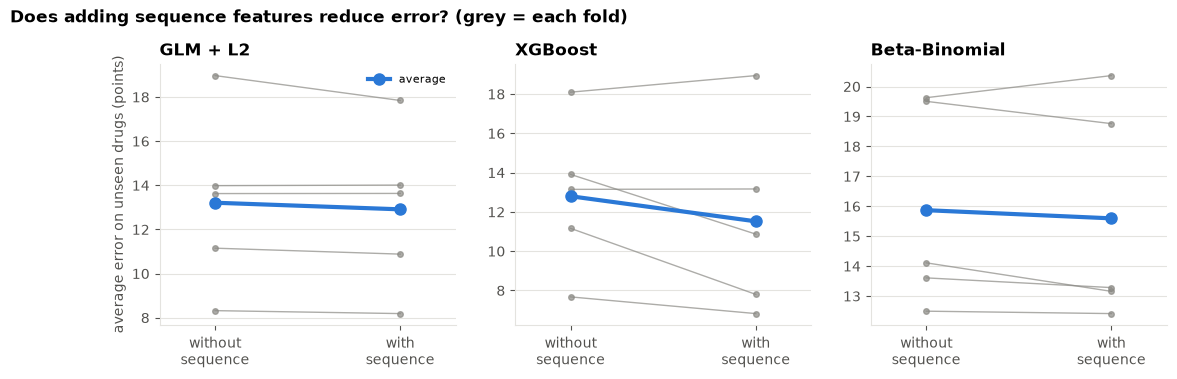

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, label in zip(axes, ["GLM + L2", "XGBoost", "Beta-Binomial"]):
    a, b = runs[(label, False)].set_index("fold"), runs[(label, True)].set_index("fold")
    for k in a.index:
        ax.plot([0, 1], [a.loc[k, "wMAE"] * 100, b.loc[k, "wMAE"] * 100], "-o", color=GRAY, ms=4, lw=1, alpha=0.7)
    ax.plot([0, 1], [a["wMAE"].mean() * 100, b["wMAE"].mean() * 100], "-o", color=BLUE, ms=8, lw=3, label="average")
    ax.set_xticks([0, 1], ["without\nsequence", "with\nsequence"]); ax.set_xlim(-0.3, 1.3)
    ax.set_title(label); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("average error on unseen drugs (points)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Does adding sequence features reduce error? (grey = each fold)", x=0.01, ha="left", fontweight="bold", y=1.04)
fig.savefig(ROOT / "figures" / "seq_go_no_go.png"); plt.show()

## 5 · Secondary analysis: only cohorts whose drug has a sequence

To make sure the missing-sequence cohorts aren't hiding an effect, we repeat the XGBoost and GLM test on the
**matched subset** (same folds, cohorts without sequence removed).

In [ ]:
sub = df[df["has_sequence"]].reset_index(drop=True)
print(f"matched subset: {len(sub)} cohorts, {sub[im.DRUG].nunique()} drugs")
sub_rows = []
for label, maker in [("GLM + L2", glm_l2_tuned), ("XGBoost", xgb_plan)]:
    res = {}
    for with_seq in [False, True]:
        pf, _ = im.cross_validate(sub, "fold_grouped", maker(im.SEQ_FEATURES if with_seq else []))
        res[with_seq] = pf.set_index("fold")
    for m in ["wMAE", "wRMSE", "loglik"]:
        d = res[True][m] - res[False][m]
        wins = int((d < 0).sum() if m != "loglik" else (d > 0).sum())
        sub_rows.append({"model": label, "metric": m, "without": res[False][m].mean(), "with sequence": res[True][m].mean(),
                         "difference": d.mean(), "folds improved": f"{wins}/5"})
display(pd.DataFrame(sub_rows).style.format({"without": "{:.4f}", "with sequence": "{:.4f}", "difference": "{:+.4f}"}).hide(axis="index"))

matched subset: 1566 cohorts, 104 drugs


model,metric,without,with sequence,difference,folds improved
GLM + L2,wMAE,0.1325,0.1296,-0.0028,4/5
GLM + L2,wRMSE,0.1780,0.1758,-0.0022,4/5
GLM + L2,loglik,-19.1303,-18.2608,+0.8695,4/5
XGBoost,wMAE,0.1335,0.1159,-0.0177,4/5
XGBoost,wRMSE,0.1873,0.1767,-0.0107,4/5
XGBoost,loglik,-22.8235,-22.2868,+0.5366,3/5


## 6 · Decision and Days 11–12 findings

**Coverage:** 104 of 137 drug products (76 distinct sequences) and **89 % of cohorts** have a sequence. That is above the 50 % rule, so the main test uses all cohorts. None of the 6 bacterial drugs has one.

**Drug-level look:** no single sequence feature shows a strong monotone relation with ADA (see the Spearman ρ values in section 2). Most drugs are IgG antibodies whose whole-molecule properties are very similar, because the shared constant regions dominate.

**Pre-registered test on unseen molecules** (grouped CV, with minus without sequence features):

| model | wMAE | folds improved | other metrics | passes rule? |
|---|---|---|---|---|
| GLM + L2 | 0.132 → 0.129 | 3/5 | wRMSE ≈ same; loglik slightly worse | **no** |
| XGBoost | 0.128 → **0.115** | 3/5 (fold SD of gain 1.9 pts) | wRMSE 0.180 → 0.177 (3/5); loglik ≈ same | **no** |
| Beta-Binomial | 0.159 → 0.156 | 4/5 | log predictive score slightly worse (2/5); coverage 87.6 % → 85.4 % | **no** (not consistent across metrics) |

**Matched subset** (only cohorts whose drug has a sequence, 1,566 cohorts): XGBoost improves wMAE 0.134 → 0.116 and wRMSE 0.187 → 0.177 in **4/5 folds**, and GLM + L2 improves slightly on all three metrics in 4/5 folds.

**Decision: NO-GO for the main models. "Tested; no consistent improvement."** The sequence features are **not** added to the final models or the dashboard. Reasons:
1. On the full data, no model meets the pre-registered rule (better on average **and** in ≥ 4/5 folds).
2. XGBoost's average gain (−1.3 points) is large but inconsistent (3/5 folds), and it does not improve probability quality.
3. **An important lesson along the way:** our first run grouped folds by *product*, and XGBoost + sequence looked much better (wMAE 0.107). That was **leakage**: biosimilars share the originator's exact sequence, so the model recognised molecules it had already seen. After grouping by *molecule*, half of the apparent gain disappeared. All notebooks now use molecule groups.

**Honest interpretation for the report:** simple whole-molecule physico-chemical features give, at best, a **hint** of extra signal (the matched-subset XGBoost result), but not a reliable improvement for new molecules. Likely reasons: (i) most drugs are IgG antibodies whose whole-molecule properties are nearly identical; (ii) only ~76 distinct sequences; (iii) immunogenicity depends on specific regions (variable domains, T-cell epitopes), not whole-molecule averages. **Future work:** variable-region-only features, humanness scores against human germline genes, and T-cell epitope predictions.